# Hands-on Language dan Multimodal Reasoning

Notebook ini menggunakan **Qwen2.5-VL-3B-Instruct** untuk menggabungkan image dan natural-language instruction.

Versi ini dioptimalkan untuk **Google Colab T4 (±15 GB VRAM)** dengan:

- FP16,
- pembatasan visual token,
- resize image,
- `torch.inference_mode()`,
- `max_new_tokens=128`,
- pembersihan CUDA memory.

> Jika sebelumnya sudah terjadi `CUDA out of memory`, pilih **Runtime → Restart session** sebelum menjalankan notebook dari awal.


## 1. Install Library

Gunakan GPU runtime:

```text
Runtime → Change runtime type → T4 GPU
```


In [1]:
!pip -q install -U transformers accelerate qwen-vl-utils pillow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 67.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 15.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## 2. Mount Google Drive dan Tentukan Folder Project

Notebook dibuka dari Google Drive, tetapi runtime Colab tetap mulai dari `/content`.

Karena itu, Google Drive perlu di-mount lalu notebook berpindah langsung ke folder project. Notebook ini **tidak melakukan recursive scan ke seluruh Google Drive**.


In [2]:
# Mount Google Drive.
from google.colab import drive

drive.mount(
    "/content/drive"
)

# Import library untuk path.
import os
import sys
from pathlib import Path

# Folder project di Google Drive.
PROJECT_DIR = Path(
    "/content/drive/MyDrive/00. Artificial Intelligence (AI)/"
    "Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/"
    "Bagian 4 — Bagaimana Robot Mengambil Keputusan?/"
    "Handson/Language dan Multimodal Reasoning"
)

# Cek folder project.
if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        "Project directory not found:\n"
        f"{PROJECT_DIR}\n\n"
        "Jika nama folder di Google Drive sedikit berbeda, "
        "ubah hanya nilai PROJECT_DIR pada cell ini."
    )

# Pindah ke folder project.
os.chdir(
    PROJECT_DIR
)

# Tambahkan folder project ke Python import path.
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_DIR),
    )

print(
    "Project directory:",
    PROJECT_DIR,
)

print(
    "Current working directory:",
    Path.cwd(),
)

print(
    "Google Drive setup completed."
)


Mounted at /content/drive
Project directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning
Current working directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning
Google Drive setup completed.


## 3. Verifikasi Folder Project


In [3]:
# File utama yang diharapkan.
expected_files = [
    "run_vlm.py",
    "multimodal_utils.py",
    "requirements.txt",
]

print(
    "Project files:"
)

for filename in expected_files:
    path = PROJECT_DIR / filename

    print(
        f"- {filename}:",
        "OK" if path.exists() else "MISSING",
    )

# Folder hasil.
RESULTS_DIR = (
    PROJECT_DIR
    / "results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "Results directory:",
    RESULTS_DIR,
)


Project files:
- run_vlm.py: OK
- multimodal_utils.py: OK
- requirements.txt: OK
Results directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning/results


## 4. Import Library dan Bersihkan Memory


In [4]:
# Mengurangi risiko fragmentasi memory CUDA.
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

# Import library.
import gc
from pathlib import Path

import torch
from PIL import Image
from google.colab import files

from transformers import (
    AutoProcessor,
    Qwen2_5_VLForConditionalGeneration,
)

# Folder results sudah dibuat pada Google Drive.
print(
    "Results directory:",
    RESULTS_DIR,
)

# Membersihkan memory dari object lama.
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )

    print(
        "Allocated before loading:",
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB",
    )
else:
    raise RuntimeError(
        "Please enable a GPU runtime."
    )


Results directory: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning/results
GPU: Tesla T4
Allocated before loading: 0.00 GB


## 5. Siapkan dan Resize Image

Image dibatasi maksimal sekitar **1024 px** pada sisi terpanjang agar visual token tidak terlalu banyak.


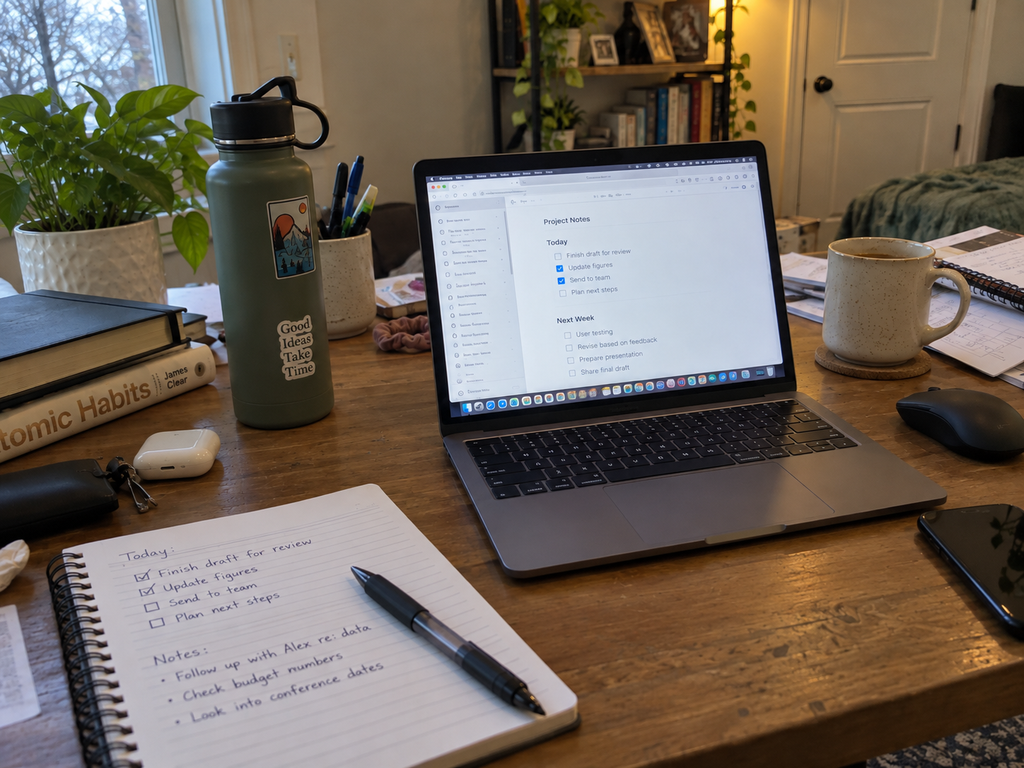

Image loaded from: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning/scene.jpg
Image size: (1024, 768)


In [5]:
# Gunakan scene.jpg dari folder project.
image_path = (
    PROJECT_DIR
    / "scene.jpg"
)

# Jika scene.jpg belum ada, upload image secara manual.
if not image_path.exists():
    print(
        "scene.jpg was not found in the project folder."
    )

    uploaded = files.upload()

    uploaded_name = list(
        uploaded.keys()
    )[0]

    image_path = (
        PROJECT_DIR
        / uploaded_name
    )

# Membuka image.
image = Image.open(
    image_path
).convert(
    "RGB"
)

# Memperkecil image jika terlalu besar.
image.thumbnail(
    (1024, 1024),
    Image.Resampling.LANCZOS,
)

# Menampilkan image.
display(
    image
)

print(
    "Image loaded from:",
    image_path,
)

print(
    "Image size:",
    image.size,
)


## 6. Masukkan Language Instruction


In [6]:
instruction = (
    "Ambil botol di sebelah laptop."
)

print(
    "Instruction:",
    instruction,
)


Instruction: Ambil botol di sebelah laptop.


## 7. Load Qwen2.5-VL-3B-Instruct

Untuk T4 kita menggunakan **FP16** dan membatasi jumlah visual token melalui `min_pixels` dan `max_pixels`.


In [7]:
MODEL_ID = (
    "Qwen/Qwen2.5-VL-3B-Instruct"
)

# Membatasi jumlah visual token.
min_pixels = 256 * 28 * 28
max_pixels = 512 * 28 * 28

# Load processor.
processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    min_pixels=min_pixels,
    max_pixels=max_pixels,
)

# Load model menggunakan FP16 agar lebih hemat VRAM.
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    low_cpu_mem_usage=True,
)

model.eval()

print(
    "Model loaded successfully."
)

print(
    "Allocated after loading:",
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB",
)


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

Model loaded successfully.
Allocated after loading: 6.99 GB


## 8. Membuat Multimodal Prompt

Prompt meminta model menentukan target object, alasan visual, dan suggested robot action.


In [8]:
prompt = f'''
You are helping a robot understand a visual scene.

Human instruction:
"{instruction}"

Look at the image and answer these points:
1. Which visible object is the instruction referring to?
2. What visual evidence supports your answer?
3. What simple robot action should be taken next?

Keep the answer concise and practical.
'''.strip()

messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image,
            },
            {
                "type": "text",
                "text": prompt,
            },
        ],
    }
]


## 9. Inference

`max_new_tokens` dibatasi ke **128** agar kebutuhan memory saat generation tetap ringan.


In [9]:
# Membuat text template.
text = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
)

# Menyiapkan input multimodal.
inputs = processor(
    text=[text],
    images=[image],
    padding=True,
    return_tensors="pt",
)

# Memindahkan input ke device model.
inputs = inputs.to(
    model.device
)

# Inference tanpa gradient.
with torch.inference_mode():
    generated_ids = model.generate(
        **inputs,
        max_new_tokens=128,
        do_sample=False,
    )

print(
    "Inference completed."
)


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


Inference completed.


## 10. Decode dan Simpan Hasil


In [10]:
# Mengambil token output baru.
generated_ids_trimmed = [
    output_ids[
        len(input_ids):
    ]
    for input_ids, output_ids
    in zip(
        inputs.input_ids,
        generated_ids,
    )
]

# Decode output.
output_text = processor.batch_decode(
    generated_ids_trimmed,
    skip_special_tokens=True,
    clean_up_tokenization_spaces=False,
)

response = output_text[0]

print(
    response
)

# Menyimpan response.
output_path = (
    RESULTS_DIR
    / "vlm_response.txt"
)

output_path.write_text(
    response + "\n",
    encoding="utf-8",
)

print(
    "\nResponse saved to:",
    output_path,
)


1. The instruction is referring to the water bottle.
2. Visual evidence includes the green water bottle with a black lid, which is placed on the left side of the laptop.
3. The robot should pick up the water bottle from its current position.

Response saved to: /content/drive/MyDrive/00. Artificial Intelligence (AI)/Mengenal Embodied AI: Dari Teori, Simulasi hingga Robot Nyata/Bagian 4 — Bagaimana Robot Mengambil Keputusan?/Handson/Language dan Multimodal Reasoning/results/vlm_response.txt
